In [2]:
from pathlib import Path
from visualize import Embedding


# use embedded fonts for matplotlib
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rc('pdf', fonttype=42)


EXPERIMENT_NAME="ro-en.128_model"
CACHE_FOLDER = f"/ivi/ilps/projects/cnmt/knn-mt-dispersion/sergey/notebook_results/{EXPERIMENT_NAME}"
PLOT_FOLDER = f"notebook_results/{EXPERIMENT_NAME}/plots"
Path(CACHE_FOLDER).mkdir(parents=True, exist_ok=True)
Path(PLOT_FOLDER).mkdir(parents=True, exist_ok=True)

# baseline ro_en
baseline = Embedding(
        name="baseline (ro-en)",
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/00408_baseline_dim128/',
        features_path='train.features.npy',
        targets_path='train.targets.npy',
        yaml_path=None,
        faiss_path='roen.faiss_l2_IVFPQindex_cs64_nprobe32_d128_nc2048',
        args={
            'nprobe': 32,
            'nclusters': 2048,
            'nsubquantizers': 64,
            'nbits': 8,
            'metric': 'L2',
            'index_type': 'IVFPQ',
            'ntotal': 21507934,
            'dim': 128
        }
    )
# dispersion ro_en
dispersion = Embedding(
        name="dispersion (ro-en)",
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/00591_ftdispersion_dim128/',
        features_path='train.features.npy',
        targets_path='train.targets.npy',
        yaml_path=None,
        faiss_path='roen.faiss_L2_IVFPQindex_cs64_nprobe32_d128_nc2048',
        args={
            'nprobe': 32,
            'nclusters': 2048,
            'nsubquantizers': 64,
            'nbits': 8,
            'metric': 'L2',
            'index_type': 'IVFPQ',
            'ntotal': 21507934,
            'dim': 128
        }
    )
baseline.load()
dispersion.load()


# caching the slice of the data
subsample_size = 1000000


# baseline.cache_features_and_targets(
#     cache_folder=CACHE_FOLDER,
#     cache_name='subsampled_features_targets',
#     subsample_size=subsample_size
# )
# dispersion.cache_features_and_targets(
#     cache_folder=CACHE_FOLDER,
#     cache_name='subsampled_features_targets',
#     subsample_size=subsample_size
# )

/home/stroshi/miniconda3/envs/evgeniia/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Namespace(dim=128, index_type='IVFPQ', metric='L2', nbits=8, nclusters=2048, nprobe=32, nsubquantizers=64, ntotal=21507934)
Namespace(dim=128, index_type='IVFPQ', metric='L2', nbits=8, nclusters=2048, nprobe=32, nsubquantizers=64, ntotal=21507934)


In [3]:
baseline.load_subsampled_features_and_targets(
    cache_folder=CACHE_FOLDER,
    cache_name='subsampled_features_targets'
)
dispersion.load_subsampled_features_and_targets(
    cache_folder=CACHE_FOLDER,
    cache_name='subsampled_features_targets'
)
assert baseline.sampled_keys.shape == dispersion.sampled_keys.shape
assert baseline.sampled_targets.shape == dispersion.sampled_targets.shape
assert baseline.sampled_keys.shape[0] == subsample_size
assert baseline.sampled_targets.shape[0] == subsample_size

loading subsample of keys and targets from /ivi/ilps/projects/cnmt/knn-mt-dispersion/sergey/notebook_results/ro-en.128_model/subsampled_features_targets/baseline (ro-en).npz
size of all keys/targets 21507934
size of subsample 1000000
loading subsample of keys and targets from /ivi/ilps/projects/cnmt/knn-mt-dispersion/sergey/notebook_results/ro-en.128_model/subsampled_features_targets/dispersion (ro-en).npz
size of all keys/targets 21507934
size of subsample 1000000


In [4]:
BASELINE_LINE_COLOR = "tab:blue"
BASELINE_LINE_STYLE = "dashed"

DISPERSION_LINE_COLOR = "tab:orange"
DISPERSION_LINE_STYLE = "solid"

DPI = 200

## TODO
- store the subsample for each features/targets

## Plans
-  cluster entropy (as a discrete histogram of points per center) and (related) average and median cluster size
-  total kmeans energy sum_i d^2 (x_i, q(x_i))
-  per-cluster energy for cluster z = sum_{x : q(x)=z} d^2(x, z)}
-  For every point, what % of its k nearest neighbors lie in the same cluster as the point (fix k to be what is used in decoding)
-  clustering evaluation metrics from sklearn (eg v -measure etc, using the token labels ("values" in the kv store) as labels (edited) 

saved plot to notebook_results/ro-en.128_model/plots/cluster_sizes.png


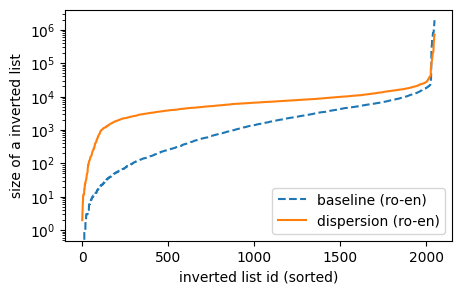

baseline (ro-en)
           mean  median
0  10501.920898  1492.0

dispersion (ro-en)
           mean  median
0  10501.920898  6628.0


In [5]:
import numpy as np
import pandas as pd
import numpy as np
import scipy as sp

from typing import List, Tuple

def cluster_entropy(embedding: Embedding):
    """
    Returns: IVF cluster sizes
    """
    knn_index = embedding.knn_index
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))
    return sizes

def make_sizes_plot(baseline: Embedding, dispersion: Embedding):
    """
    Plot the sizes of the IVF clusters for the baseline and dispersion embeddings.
    default: sorted mode by the size of the inverted list
    """
    sizes_baseline = cluster_entropy(baseline)
    sizes_dispersion = cluster_entropy(dispersion)
    sizes_baseline = np.sort(sizes_baseline)
    sizes_dispersion = np.sort(sizes_dispersion)

    fig, ax = plt.subplots(figsize=(5, 3))
    plt.plot(sizes_baseline, label=baseline.name, color=BASELINE_LINE_COLOR, linestyle=BASELINE_LINE_STYLE)
    plt.plot(sizes_dispersion, label=dispersion.name, color=DISPERSION_LINE_COLOR, linestyle=DISPERSION_LINE_STYLE)
    # put the legend in the upper right corner but a bit to the left
    ax.legend(loc='lower right')
    ax.set_ylabel('size of a inverted list')
    ax.set_xlabel('inverted list id (sorted)')
    # log scale
    ax.set_yscale('log')
    plt.savefig(f"{PLOT_FOLDER}/cluster_sizes.png", dpi=DPI, bbox_inches='tight')
    print("saved plot to", f"{PLOT_FOLDER}/cluster_sizes.png")
    plt.show()


def make_mean_median_cluster_sizes(embedding) -> pd.DataFrame:
    sizes = cluster_entropy(embedding)
    sizes = np.array(sizes)
    mean = np.mean(sizes)
    median = np.median(sizes)
    df = pd.DataFrame({'mean': [mean], 'median': [median]})
    return df


########### script. ##########

make_sizes_plot(baseline, dispersion)

# make mean and median cluster sizes
df_baseline = make_mean_median_cluster_sizes(baseline)
df_dispersion = make_mean_median_cluster_sizes(dispersion)

print(baseline.name)
print(df_baseline)
print()
print(dispersion.name)
print(df_dispersion)


- why mean is *exactly* the same for baseline and dispersion?
- dispersion makes clusters more equal in size

Baseline total kmeans energy: 1907702.0 +- 4075.4360959218006
Dispersion total kmeans energy: 1777823.25 +- 3730.5780753598688


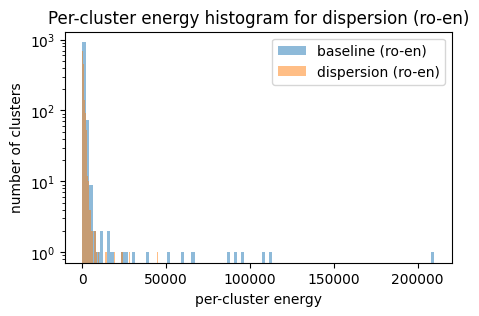

In [5]:
def sample_d_i_ivf_kmeans(embedding: Embedding, n_sample=10000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature)
    keys = embedding.sampled_keys
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    D, I = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    return D.flatten(), I.flatten()


def total_kmeans_energy(embedding) -> Tuple[float, float]:
    """
    Returns:
    total kmeans energy sum_i d^2 (x_i, q(x_i))
    lower and upper confidence intervals
    """
    # total kmeans energy with std
    energies = []
    for seed in range(5):
        dss, _ = sample_d_i_ivf_kmeans(embedding, n_sample=10000, seed=seed)
        energy = np.sum(dss)
        energies.append(energy)
    # calculate mean and std
    # for the energies
    mean = np.mean(energies)
    std = sp.stats.sem(energies)
    return mean, std


def per_cluster_energy(embedding) -> List[float]:
    #  per-cluster energy for cluster z = sum_{x : q(x)=z} d^2(x, z)}
    dss, ids = sample_d_i_ivf_kmeans(embedding, n_sample=10000)
    energies = []
    for id in np.sort(np.unique(ids)):
        indices_with_id = np.where(ids == id)[0]
        dss_for_id = dss[indices_with_id]
        energies.append(dss_for_id.sum())
    return energies


print("Baseline total kmeans energy: {} +- {}".format(*total_kmeans_energy(baseline)))
print("Dispersion total kmeans energy: {} +- {}".format(*total_kmeans_energy(dispersion)))


# make a histogram of the per-cluster energy
def make_per_cluster_energy_histogram(energies, embedding, ax):
    ax.hist(energies, bins=100, label=embedding.name, alpha=0.5)
    ax.set_xlabel('per-cluster energy')
    ax.set_ylabel('number of clusters')
    ax.set_title(f'Per-cluster energy histogram for {embedding.name}')
    ax.set_yscale('log')

fig, ax = plt.subplots(figsize=(5, 3))
make_per_cluster_energy_histogram(
    per_cluster_energy(baseline),
    baseline, ax
)
make_per_cluster_energy_histogram(
    per_cluster_energy(dispersion),
    dispersion, ax
)
ax.legend()
plt.savefig(f"{PLOT_FOLDER}/per_cluster_energy_histogram.png", dpi=DPI, bbox_inches='tight')
plt.show()


- for dispersion it seems that the energy is lower. stds over 5 seeds to not intersect (check that I do it correctly!) - (2305178.5 - 19027.875), (1989874.0 + 25213.955078125) = (2286150.625, 2015087.955078125)
- Currently to speed up things I crop first N points to speed up reading from the disk, but should sample from all points for the final run?

## avg nprobes to cover k

For a point x, first, rank the centroids by distance to q(x). 

let's call this ranking R. (so the centroid closest to q(x) is 1, ie R(q(x))=1. the second-closest is 2, so R(argmin_z {d(z, x): z != q(x))} = 2, etc). In case of ties take the average ranking among the ties.

Then retrieve k nearest neighbors of x, and compute the ranks of the centroids where these neighbors belong to.



In [6]:
d = [0.1, 0.0, 0.4, 0.5, 0.3]
argsort = np.argsort(d)
rank = np.empty_like(argsort)
rank[argsort] = np.arange(len(d))
print(rank)

[1 0 3 4 2]


In [11]:
def extract_centroids(embedding) -> np.ndarray:
    """Return:
    np.ndarray of centroids for IVF clusters
    """
    return embedding.knn_index.quantizer.reconstruct_n(0, embedding.knn_index.invlists.nlist)

def rank_centroids_by_distance_to_keys(keys: np.ndarray, centroids: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    "Returns a matrix of ranks and distances for each centroid to each key"
    "np.ndarray of shape (n_keys, n_centroids)"

    # calculate eucledian distances in matrix form
    assert keys.shape[-1] == centroids.shape[-1]
    assert keys.ndim == 2 and centroids.ndim == 2
    
    distances = np.linalg.norm(keys[:, np.newaxis] - centroids, axis=-1)
    # for each position in distances, store its rank in sort
    order = np.argsort(distances, axis=-1)
    ranks = np.argsort(order, axis=-1) + 1  # ranks start from 1
    return ranks, distances

def get_closest_centroid(keys: np.ndarray, centroids: np.ndarray) -> np.ndarray:
    """Return:
    closest centroid to the key
    """
    assert keys.shape[-1] == centroids.shape[-1]
    assert keys.ndim == 2 and centroids.ndim == 2
    distances = np.linalg.norm(keys[:, np.newaxis] - centroids, axis=-1)
    # rank the distances
    rank = np.argmin(distances, axis=-1)
    return rank


def find_k_true_nearest_neighbors(querries: np.ndarray, keys: np.ndarray, k: int) -> Tuple[np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature) 
    assert keys.ndim == 2
    assert keys.shape[-1] == querries.shape[-1]

    nearest_neighbors = np.zeros((querries.shape[0], k), dtype=np.int32)
    distances_knn = np.zeros((querries.shape[0], k), dtype=np.float32)

    for i, key in enumerate(querries):
        # calculate eucledian distances in matrix form
        assert key.shape[-1] == keys.shape[-1]
        assert key.ndim == 1 and keys.ndim == 2
        distances = np.linalg.norm(key - keys, axis=-1)
        # rank the distances
        nearest_neighbors[i][:] = np.argsort(distances)[:k]
        distances_knn[i][:] = distances[nearest_neighbors[i]]
    return distances_knn, nearest_neighbors



def get_rank_list(closest_centroids: np.ndarray, centroids_ranks: np.ndarray) -> float:
    """
    for each querry (first axis), for each of the centroids of the k nearest 
    """
    ranks = np.zeros(closest_centroids.shape, dtype=np.float32)
    for i in range(closest_centroids.shape[0]):
        closest_c = closest_centroids[i]
        ranks_list = centroids_ranks[i]
        ranks[i] = ranks_list[closest_c]
    return ranks

# def extract_keys_fast(ids: np.ndarray, keys: np.ndarray) -> np.ndarray:
#     """
#     keys are loaded via memmap, so we need to extract them in a way that
#     doesn't require loading the whole array into memory.
#     We use sorting to turn random access into one big sequential read.
#     """
#     # remember original shape
#     shape_ids = ids.shape
#     # flatten to 1D
#     flat_ids = ids.reshape(-1)

#     # sort and keep track of order
#     sort_order = np.argsort(flat_ids)
#     sorted_ids = flat_ids[sort_order]

#     # do one memmap read of all needed rows in ascending order
#     sorted_keys = keys[sorted_ids]  # shape (len(sorted_ids), dim)

#     # invert the sort to restore original ordering
#     inv_order = np.argsort(sort_order)
#     flat_out = sorted_keys[inv_order]

#     # reshape back to original ids-shape + feature dimension
#     dim = keys.shape[1]
#     extracted_keys = flat_out.reshape(*shape_ids, dim)
#     return extracted_keys


def estimate_MRAR(embedding: Embedding, k=10, n_querries=100, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """Estimate the MRAR for the embedding
    Returns:
    distances and indices of the k nearest neighbors
    """
    # save values and corresponding cluster_id(feature) 
    np.random.seed(seed)
    sampled_keys = embedding.sampled_keys
    querries = sampled_keys[np.random.choice(len(sampled_keys), n_querries, replace=False)]

    centroids = extract_centroids(embedding)

    centroids_ranks_per_querry = rank_centroids_by_distance_to_keys(querries, centroids)[0]

    # distances_knn, nearest_neighbors_ids = find_k_true_nearest_neighbors(querries, keys, k)
    # find nearest neighbors using the knn index
    distances_knn, nearest_neighbors_ids = embedding.knn_index.search(querries, k)
    
    nearest_neighbors = embedding.keys[nearest_neighbors_ids]
    # nearest_neighbors = extract_keys_fast(nearest_neighbors_ids, embedding.keys)
    
    nearest_neighbors_reshaped = nearest_neighbors.reshape(-1, nearest_neighbors.shape[-1])
    closest_centroids = get_closest_centroid(nearest_neighbors_reshaped, centroids)
    closest_centroids = closest_centroids.reshape(nearest_neighbors.shape[0], -1)

    rank_list = get_rank_list(closest_centroids, centroids_ranks_per_querry)
    print("nprobes", embedding.knn_index.nprobe, "n_querries", n_querries, "k", k)
    print("rank list [:10]", rank_list[:10])

    MRAR = np.mean(rank_list, axis=-1)
    mean_MRAR = np.mean(MRAR)
    std_MRAR = sp.stats.sem(MRAR)
    print("MRAR: {} +- {}".format(mean_MRAR, std_MRAR))

    max_rank = np.max(rank_list, axis=-1)
    median_max_rank = np.median(max_rank)
    mean_max_rank = np.mean(max_rank)
    std_max_rank = sp.stats.sem(max_rank)
    print("mean max rank (expected n probles to get k correct): {} +- {}".format(mean_max_rank, std_max_rank))
    print("median max rank: {}".format(median_max_rank))

    metrics = {
        "MRAR": (mean_MRAR, std_MRAR),
        "expected_n_probs": (mean_max_rank, std_max_rank),
        "median_max_rank": median_max_rank
    }
    return metrics


args = {
    "k": 8,
    "n_querries": 500,
    "seed": 0
}
metrics_baseline = estimate_MRAR(baseline, **args)
metrics_dispersion = estimate_MRAR(dispersion, **args)

# print with 3 decimal points
print("Baseline MRAR: {:.3f} +- {:.3f}".format(*metrics_baseline["MRAR"]))
print("Dispersion MRAR: {:.3f} +- {:.3f}".format(*metrics_dispersion["MRAR"]))
print("Baseline expected n probes: {:.3f} +- {:.3f}".format(*metrics_baseline["expected_n_probs"]))
print("Dispersion expected n probes: {:.3f} +- {:.3f}".format(*metrics_dispersion["expected_n_probs"]))
print("Baseline median max rank: {:.3f}".format(metrics_baseline["median_max_rank"]))
print("Dispersion median max rank: {:.3f}".format(metrics_dispersion["median_max_rank"]))

nprobes 32 n_querries 500 k 8
rank list [:10] [[1. 4. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 2. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 3. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]]
MRAR: 2.8237500190734863 +- 0.26051208278126453
mean max rank (expected n probles to get k correct): 6.296000003814697 +- 0.6670732836390517
median max rank: 1.0
nprobes 32 n_querries 500 k 8
rank list [:10] [[ 1.  1.  1.  1.  1.  1.  1.  1.]
 [ 1.  1.  1.  1.  1.  1.  1.  1.]
 [ 1.  4.  1.  4.  1.  4.  1.  1.]
 [ 1.  1.  1.  5.  5.  5. 12. 12.]
 [ 1.  1.  1.  1.  1.  1.  1.  1.]
 [ 1.  6.  1.  1.  9.  6.  5.  1.]
 [ 1.  1.  1.  1.  1.  1.  1.  1.]
 [ 1.  5.  2.  6.  2.  1.  5.  5.]
 [ 1.  1.  1.  1.  1.  1.  1.  1.]
 [ 1.  1.  1.  1.  1.  1.  1.  1.]]
MRAR: 1.874500036239624 +- 0.09969893785712952
mean max rank (expected n probles to get k correct): 3.2899999618530273 +- 0.

In [13]:
# use sklearn to evaluate metrics
from collections import defaultdict
from sklearn.metrics import homogeneity_completeness_v_measure, silhouette_score, davies_bouldin_score, calinski_harabasz_score
import tqdm

def extract_clusters_with_labels(embedding: Embedding, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.sampled_keys # use more for final plot
    targets = embedding.sampled_targets
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    targets = targets[indices].reshape(-1, 1) # (n_sample, 1)

    D, I = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    assert D.shape == (n_sample, 1)
    assert I.shape == (n_sample, 1)
    assert targets.shape == (n_sample, 1)
    return keys, D.flatten(), I.flatten(), targets.flatten()



def clustering_metrics(clusters: Tuple[np.ndarray, np.ndarray, np.ndarray]) -> dict:
    # 1. v measure score
    keys, dists, ids, targets = clusters
    homogenity, completeness, v_measure = homogeneity_completeness_v_measure(targets, ids)
    # silhouette = silhouette_score(keys, ids)
    # davies_bouldin = davies_bouldin_score(keys, ids)
    # calinski_harabasz = calinski_harabasz_score(keys, ids)
    return {
        'v_measure': v_measure,  # 1.0 is perfect clustering,
        'homogeneity': homogenity,  # 1.0 is perfect clustering
        'completeness': completeness,  # 1.0 is perfect clustering
        # 'silhouette': silhouette,
        # 'davies_bouldin': davies_bouldin,  # lower is better
        # 'calinski_harabasz': calinski_harabasz,  # higher is better
    }

metrics_baseline = defaultdict(list)
metrics_dispersion = defaultdict(list)
for seed in tqdm.tqdm(range(3)):
    baseline_clusters = extract_clusters_with_labels(baseline, n_sample=1000000, seed=seed)
    dispersion_clusters = extract_clusters_with_labels(dispersion, n_sample=1000000, seed=seed)
    m = clustering_metrics(baseline_clusters)
    for k, v in m.items():
        metrics_baseline[k].append(v)
    m = clustering_metrics(dispersion_clusters)
    for k, v in m.items():
        metrics_dispersion[k].append(v)
# calculate mean and std
for k, v in metrics_baseline.items():
    metrics_baseline[k] = (np.mean(v), sp.stats.sem(v))
for k, v in metrics_dispersion.items():
    metrics_dispersion[k] = (np.mean(v), sp.stats.sem(v))
print("Baseline metrics")
print("=============")
for k, v in metrics_baseline.items():
    print(f"{k}: {v[0]:4f} +- {v[1]:4f}")
print()
print("Dispersion metrics")
print("=============")
for k, v in metrics_dispersion.items():
    print(f"{k}: {v[0]:4f} +- {v[1]:4f}")


    


100%|██████████| 3/3 [01:22<00:00, 27.36s/it]

Baseline metrics
v_measure: 0.515387 +- 0.000000
homogeneity: 0.444113 +- 0.000000
completeness: 0.613911 +- 0.000000

Dispersion metrics
v_measure: 0.719792 +- 0.000000
homogeneity: 0.739002 +- 0.000000
completeness: 0.701557 +- 0.000000


/tmp/ipykernel_2326737/943485164.py:36: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(hspace=0.5, wspace=0.5)
/tmp/ipykernel_2326737/943485164.py:43: UserWarning: The figure layout has changed to tight
  fig.tight_layout(pad=1.0, w_pad=0.5, h_pad=0.5)


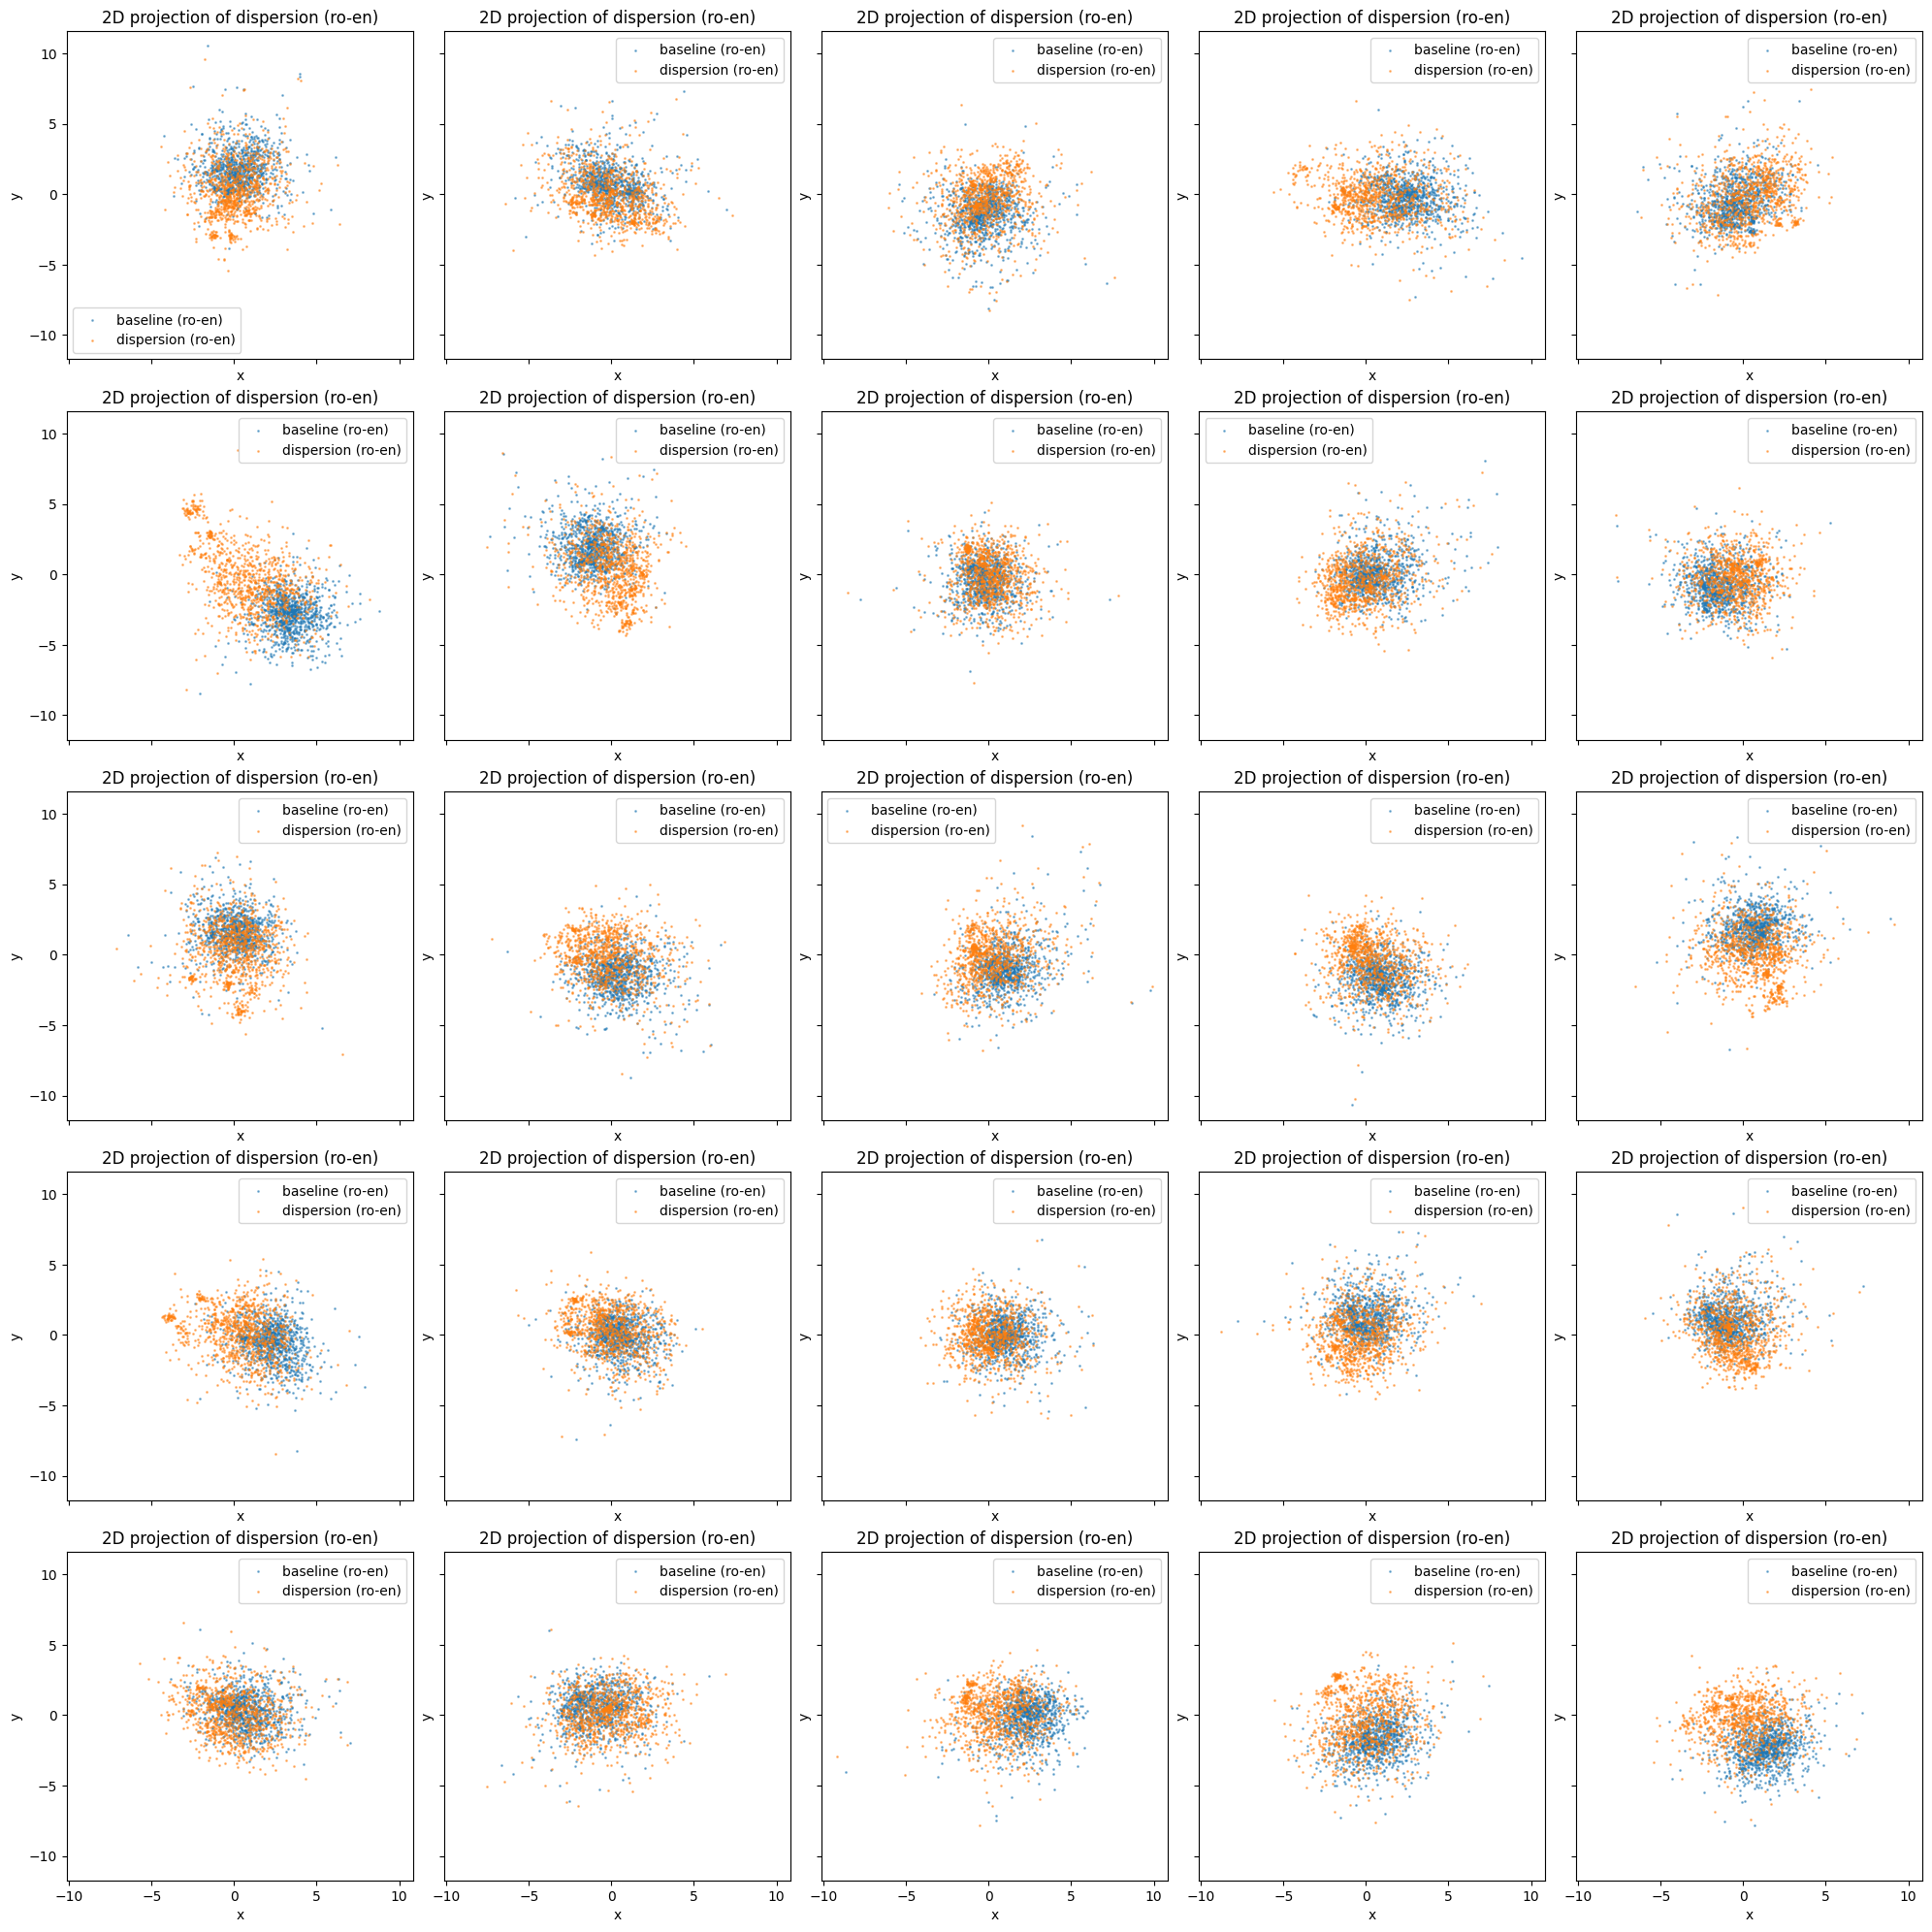

In [19]:
def random_2d_projection(embedding: Embedding, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """
    Project the keys onto a random 2D plane
    Return np.ndarray of shape (n_sample, 2)
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.sampled_keys  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    
    # project the keys onto a random 2D plane
    # generate a random 2D matrix
    random_matrix = np.random.randn(2, keys.shape[1])
    random_matrix = random_matrix / np.linalg.norm(random_matrix, axis=1, keepdims=True)
    # project the keys onto the random matrix
    projected_keys = np.dot(keys, random_matrix.T)
    return projected_keys


def plot_2d_projection(ax, embedding, n_crop=100000, n_sample=1000, seed=0):
    """
    Plot the keys in 2D
    """
    # project the keys onto a random 2D plane
    projected_keys = random_2d_projection(embedding, n_crop=n_crop, n_sample=n_sample, seed=seed)
    # plot the keys
    ax.scatter(projected_keys[:, 0], projected_keys[:, 1], alpha=0.5, label=embedding.name, s=1)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'2D projection of {embedding.name}')
    ax.legend()


fig, axes = plt.subplots(5, 5, figsize=(20, 20), sharex=True, sharey=True, constrained_layout=True)
fig.subplots_adjust(hspace=0.5, wspace=0.5)
for i in range(5):
    for j in range(5):
        ax = axes[i, j]
        # plot the keys in 2D
        plot_2d_projection(ax, baseline,   n_sample=1000, seed=i*10+j)
        plot_2d_projection(ax, dispersion, n_sample=1000, seed=i*10+j)
fig.tight_layout(pad=1.0, w_pad=0.5, h_pad=0.5)
plt.show()



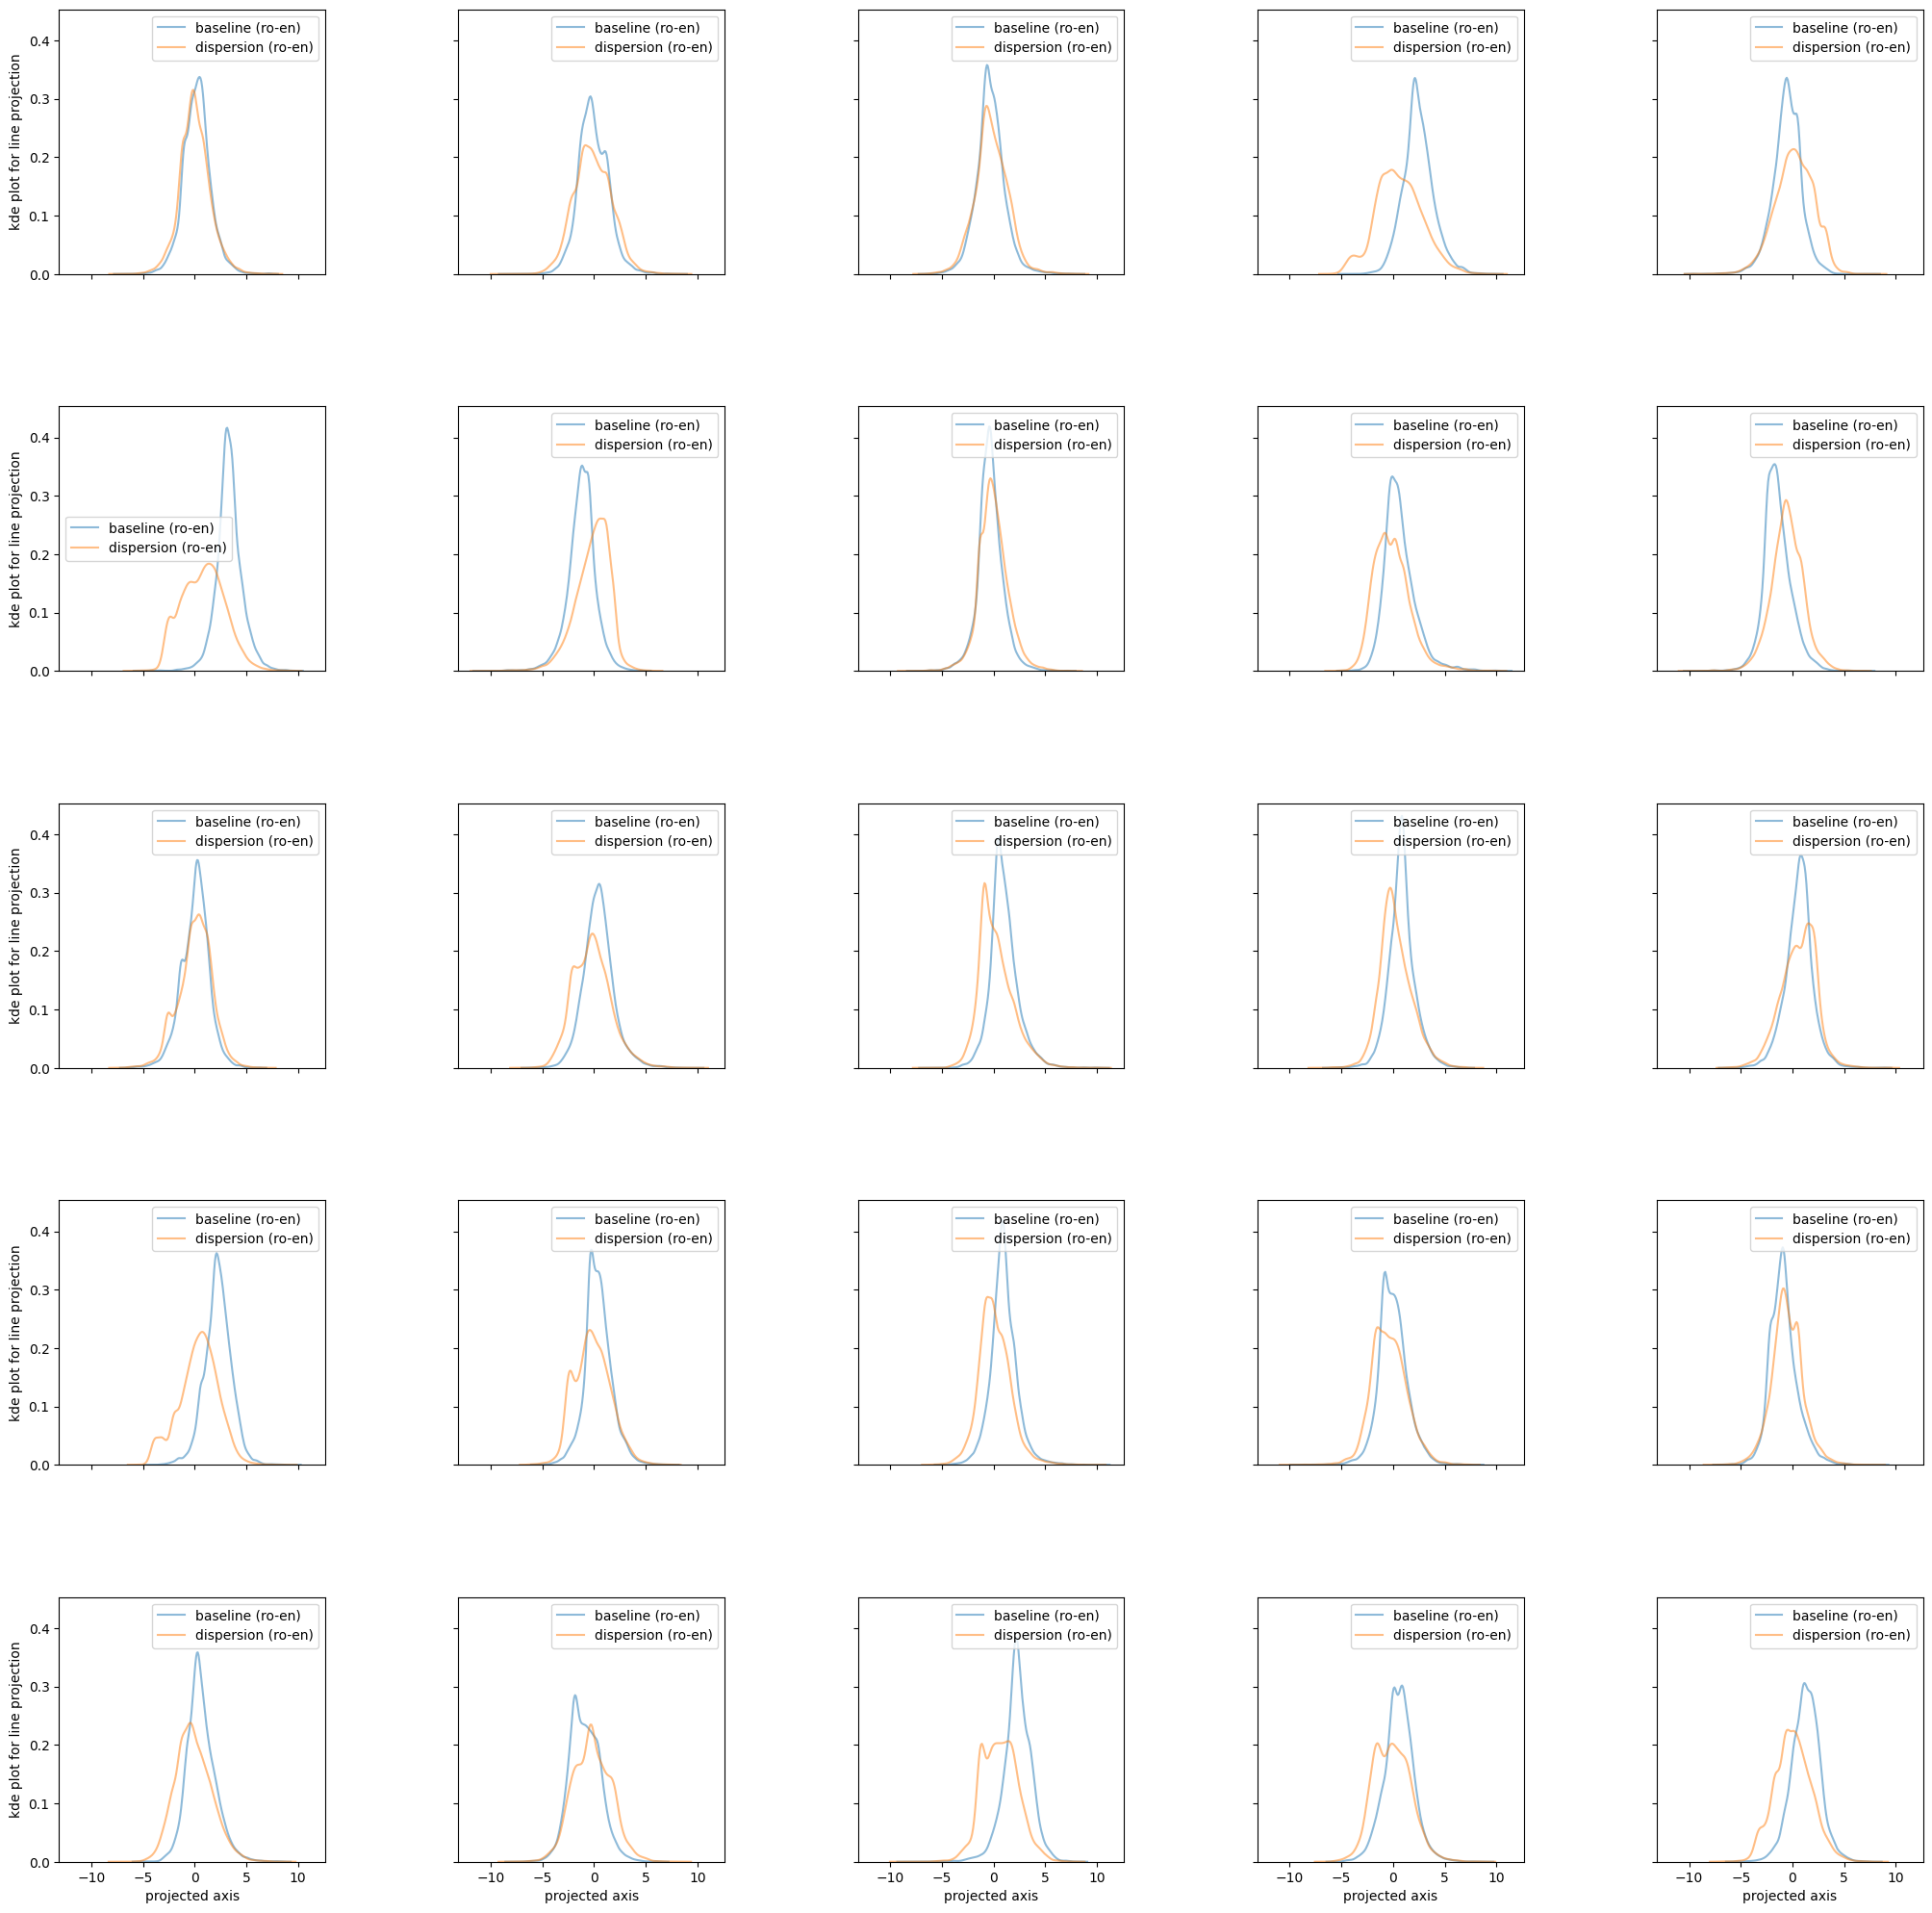

In [17]:
import seaborn as sns

def random_line_projection(embedding: Embedding, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """
    Project the keys onto a random line
    Return np.ndarray of shape (n_sample, 1)
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.sampled_keys  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    
    # project the keys onto a random line through the origin
    line = np.random.randn(keys.shape[1])
    line = line / np.linalg.norm(line)
    # project the keys onto the line
    projected_keys = np.dot(keys, line)
    return projected_keys

def plot_line_distribution(ax, embedding, n_sample=1000, seed=0):
    """
    Plot the distribution of line projections
    """
    # project the keys onto a random 2D plane
    projected_keys = random_line_projection(embedding, n_sample=n_sample, seed=seed)
    # make kde plot
    # use gaussian kernel density estimation

    # make sns.kdeplot
    sns.kdeplot(projected_keys, ax=ax, label=embedding.name, alpha=0.5)

    ax.set_xlabel('projected axis')
    ax.set_ylabel('kde plot for line projection')
    ax.legend()
    

N = 5  # N x N grid
fig, axes = plt.subplots(N, N, figsize=(N * 5, N * 5), sharex=True, sharey=True)
fig.subplots_adjust(hspace=0.5, wspace=0.5)
for i in range(N):
    for j in range(N):
        ax = axes[i, j]
        # plot the keys in 2D
        plot_line_distribution(ax, baseline, n_sample=10000, seed=i*10+j)
        plot_line_distribution(ax, dispersion, n_sample=10000, seed=i*10+j)
plt.show()



- projectted plots don't look much different

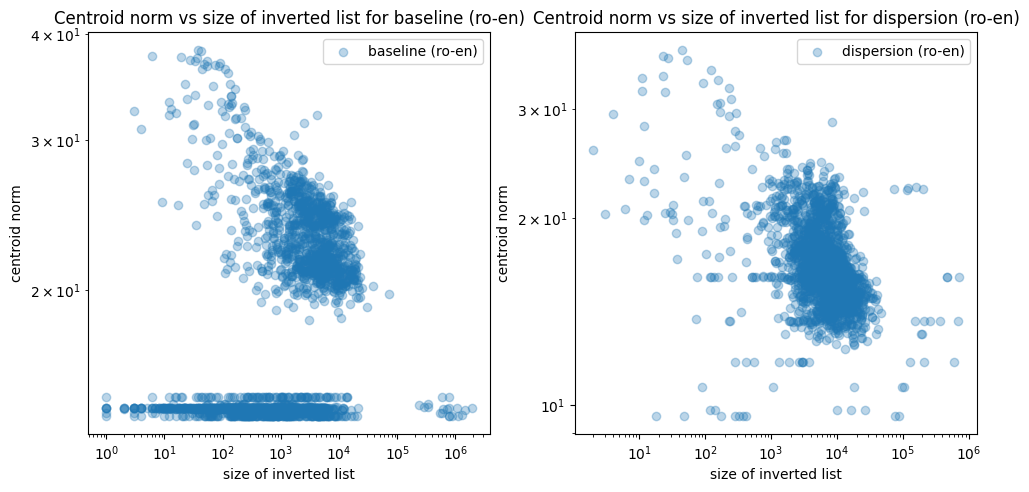

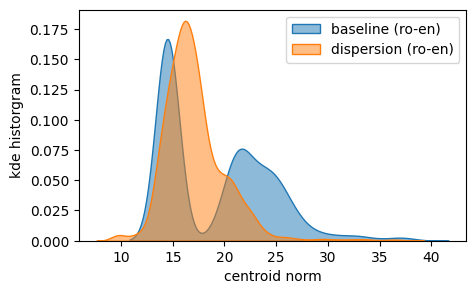

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
import seaborn as sns

from typing import List, Tuple

def cluster_entropy_with_centroids(embedding: Embedding):
    """
    Returns: IVF cluster sizes
    """
    knn_index = embedding.knn_index
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))

    centroids = knn_index.quantizer.reconstruct_n(0, knn_index.invlists.nlist)
    sizes = np.array(sizes)
    return sizes, centroids

def make_sizes_centroid_norm_plot(baseline: Embedding, dispersion: Embedding):
    """
    Plot the sizes of the IVF clusters for the baseline and dispersion embeddings.
    default: sorted mode by the size of the inverted list
    """
    sizes_baseline, centroids_baseline = cluster_entropy_with_centroids(baseline)
    sizes_dispersion, centroids_dispersion = cluster_entropy_with_centroids(dispersion)
    sorted_indices_baseline = np.argsort(sizes_baseline)
    sorted_indices_dispersion = np.argsort(sizes_dispersion)
    sizes_baseline = sizes_baseline[sorted_indices_baseline]
    sizes_dispersion = sizes_dispersion[sorted_indices_dispersion]
    centroids_baseline_norms = np.linalg.norm(centroids_baseline, axis=1)
    centroids_dispersion_norms = np.linalg.norm(centroids_dispersion, axis=1)
    centroids_baseline_norms = centroids_baseline_norms[sorted_indices_baseline]
    centroids_dispersion_norms = centroids_dispersion_norms[sorted_indices_dispersion]

    # separate plots
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].scatter(sizes_baseline, centroids_baseline_norms, label=baseline.name, alpha=0.3)
    axes[0].set_xlabel('size of inverted list')

    axes[0].set_ylabel('centroid norm')

    axes[0].set_title(f'Centroid norm vs size of inverted list for {baseline.name}')
    axes[0].set_yscale('log')
    axes[0].set_xscale('log')
    axes[0].legend()
    axes[1].scatter(sizes_dispersion, centroids_dispersion_norms, label=dispersion.name, alpha=0.3)
    axes[1].set_xlabel('size of inverted list')
    axes[1].set_ylabel('centroid norm')
    axes[1].set_title(f'Centroid norm vs size of inverted list for {dispersion.name}')
    axes[1].set_yscale('log')
    axes[1].set_xscale('log')
    axes[1].legend()
    fig.tight_layout(pad=1.0, w_pad=0.5, h_pad=0.5)
    plt.xscale('log')
    plt.show()


def plot_marginal_centroid_norms(ax, embedding, n_crop=100000, n_sample=1000, seed=0):
    """
    Plot the distribution of centroid norms
    """
    # project the keys onto a random 2D plane
    sizes, centroids = cluster_entropy_with_centroids(embedding)
    centroid_norms = np.linalg.norm(centroids, axis=1)
   
    sns.kdeplot(centroid_norms, ax=ax, label=embedding.name, alpha=0.5, fill=True)

    ax.set_xlabel('centroid norm')
    ax.set_ylabel('kde historgram')
    ax.legend()


########### script. ##########

make_sizes_centroid_norm_plot(baseline, dispersion)

fig, ax = plt.subplots(figsize=(5, 3))
plot_marginal_centroid_norms(ax, baseline, n_crop=1000000, n_sample=10000, seed=0)
plot_marginal_centroid_norms(ax, dispersion, n_crop=1000000, n_sample=10000, seed=0)
plt.show()